
# DP-SGD and DP-SignSGD: quadratic-only SDE validation

It simulates, only on the quadratic objective,

$
    f(x)=\frac{1}{2}x^\top Hx,\qquad H=0.1\operatorname{diag}(2,1,\ldots,1),\qquad d=1024,
$

1. the discrete **DP-SGD** update;
2. the discrete **DP-SignSGD** update;
3. the corresponding SDE approximations;
4. the averaged squared-gradient-norm curves;
5. the averaged two-dimensional trajectories over the first two coordinates.


## Model implemented

For the synthetic full-gradient validation, the noisy privatized gradient is modeled as

$
    g_k = C[\nabla f(x_k)+Z_{\gamma,k}] + Z_{\mathrm{DP},k},
    \qquad Z_{\mathrm{DP},k}\sim \mathcal N(0,C^2\sigma_{DP}^2 I_d),
$

with the synthetic mini-batch abstraction `B=1`. The discrete methods are

$
    x_{k+1}=x_k-\eta g_k,
    \qquad
    x_{k+1}=x_k-\eta\operatorname{sign}(g_k).
$

In [1]:

# Colab/standard imports
import math
import time
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt

try:
    from tqdm.auto import tqdm
except Exception:
    def tqdm(x, **kwargs):
        return x

%config InlineBackend.figure_formats = ['svg']


In [2]:

# Plot style close to the template notebook.
plt.rcParams.update({
    "font.size": 12,
    "figure.figsize": (7, 5),
    "axes.grid": True,
    "grid.alpha": 0.35,
})

COLORS = {
    "DP-SGD": "#CC79A7",
    "SDE DP-SGD": "#56B4E9",
    "DP-SignSGD": "#009E73",
    "SDE DP-SignSGD": "#E69F00",
}

LINESTYLES = {
    "DP-SGD": "-",
    "SDE DP-SGD": (0, (3, 2)),
    "DP-SignSGD": "-",
    "SDE DP-SignSGD": (0, (3, 1, 1, 1)),
}


In [3]:

# ============================================================
# Appendix C.1: quadratic-only configuration
# ============================================================

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DTYPE = torch.float32
print(f"Using device: {DEVICE}")

# Exact Appendix C.1 values. For a quick smoke test, set RUNS=4 and T=200.
RUNS = 200
T = 10_000
D = 1024
B = 1
C_CLIP = 5.0
SIGMA_GAMMA = 1.0 / math.sqrt(D)
NU = 1.0
DELTA = 1e-4
EPSILON = 5.0
Q = 1e-4
SIGMA_DP = 0.03

ETA_SGD = 0.1
ETA_SIGN = 0.01

# Paper-like synthetic-gradient update by default.
APPLY_CLIPPING_TO_DISCRETE = True
BATCH_NOISE_DISTRIBUTION = "gaussian"   # "student_t" or "gaussian"
SDE_MODEL = "auto_phase"                 # "auto_phase" or "phase2"

SAVE_EVERY = 1

# Reproducibility seeds.
SEEDS = {
    "x0_sgd": 123,
    "x0_sign": 456,
    "dp_sgd": 1001,
    "dp_sgd_sde": 1002,
    "dp_sign": 1003,
    "dp_sign_sde": 1004,
}


Using device: cpu


In [4]:

def K_student_t(nu: float) -> float:
    # K(nu)=sqrt(2/nu)*Gamma((nu+1)/2)/Gamma(nu/2).
    return math.sqrt(2.0 / nu) * math.gamma((nu + 1.0) / 2.0) / math.gamma(nu / 2.0)

K_NU = K_student_t(NU)
print(f"K(nu={NU:g}) = {K_NU:.6f}")


def make_h_diag(d: int, device=DEVICE, dtype=DTYPE) -> torch.Tensor:
    # Appendix C.1: H = 0.1 diag(2, 1, ..., 1).
    h = torch.ones(d, device=device, dtype=dtype)
    h[0] = 2.0
    return 0.1 * h


def loss_fn(x: torch.Tensor, h_diag: torch.Tensor) -> torch.Tensor:
    return 0.5 * (h_diag * x.pow(2)).sum(dim=1)


def grad_fn(x: torch.Tensor, h_diag: torch.Tensor) -> torch.Tensor:
    return h_diag * x


def grad_norm_sq(x: torch.Tensor, h_diag: torch.Tensor) -> torch.Tensor:
    return grad_fn(x, h_diag).pow(2).sum(dim=1)


def clip_by_l2(g: torch.Tensor, c: float, eps: float = 1e-12) -> torch.Tensor:
    norm = g.norm(dim=1, keepdim=True)
    scale = torch.clamp(c / (norm + eps), max=1.0)
    return scale * g


def make_repeated_initial(seed: int, runs: int, d: int, device=DEVICE, dtype=DTYPE) -> torch.Tensor:
    # We sample one initial point per method and reuse it across repetitions.
    gen = torch.Generator(device="cpu")
    gen.manual_seed(seed)
    x0_single = (50.0 / math.sqrt(d)) * torch.randn(d, generator=gen, dtype=dtype)
    return x0_single.to(device=device).unsqueeze(0).repeat(runs, 1)


def batch_noise(shape, sigma_gamma: float, distribution: str, nu: float, device=DEVICE, dtype=DTYPE):
    if distribution == "gaussian":
        return sigma_gamma * torch.randn(shape, device=device, dtype=dtype)
    if distribution == "student_t":
        if abs(nu - 1.0) < 1e-12:
            # Standard Cauchy sampling. Clamp only to avoid numerical inf before clipping.
            u = torch.rand(shape, device=device, dtype=dtype).clamp(1e-7, 1.0 - 1e-7)
            z = torch.tan(math.pi * (u - 0.5))
            return sigma_gamma * z.clamp(-1e6, 1e6)
        dist = torch.distributions.StudentT(df=torch.tensor(nu, device=device, dtype=dtype))
        return sigma_gamma * dist.sample(shape).to(device=device, dtype=dtype)
    raise ValueError(f"Unknown distribution: {distribution}")


def record_state(x, h_diag, grad_norm_out, traj_out, save_idx):
    grad_norm_out[save_idx] = grad_norm_sq(x, h_diag).mean().detach().cpu().item()
    traj_out[save_idx, :] = x[:, :2].mean(dim=0).detach().cpu().numpy()


K(nu=1) = 0.797885


In [5]:

@torch.no_grad()
def simulate_discrete(
    *,
    method: str,
    x0: torch.Tensor,
    eta: float,
    sigma_dp: float = SIGMA_DP,
    sigma_gamma: float = SIGMA_GAMMA,
    c_clip: float = C_CLIP,
    bsz: int = B,
    t_steps: int = T,
    save_every: int = SAVE_EVERY,
    apply_clipping: bool = APPLY_CLIPPING_TO_DISCRETE,
    noise_distribution: str = BATCH_NOISE_DISTRIBUTION,
    nu: float = NU,
    seed: int = 0,
):
    # Simulate the discrete DP-SGD or DP-SignSGD synthetic update.
    torch.manual_seed(seed)
    if DEVICE == "cuda":
        torch.cuda.manual_seed_all(seed)

    h_diag = make_h_diag(x0.shape[1])
    x = x0.clone()
    n_save = t_steps // save_every + 1
    gnorm = np.empty(n_save, dtype=np.float64)
    traj = np.empty((n_save, 2), dtype=np.float64)

    record_state(x, h_diag, gnorm, traj, 0)
    save_idx = 1
    dp_std = c_clip * sigma_dp / bsz

    for k in tqdm(range(1, t_steps + 1), desc=f"discrete / {method}", leave=False):
        grad = grad_fn(x, h_diag)

        # B=1 is the synthetic setting used here. If B>1, use the Gaussian average approximation.
        if bsz == 1:
            z_gamma = batch_noise(grad.shape, sigma_gamma, noise_distribution, nu, device=x.device, dtype=x.dtype)
        else:
            z_gamma = (sigma_gamma / math.sqrt(bsz)) * torch.randn_like(grad)

        g = grad + z_gamma
        if apply_clipping:
            g = clip_by_l2(g, c_clip)

        g_private = g + dp_std * torch.randn_like(g)

        if method == "dp_sgd":
            x = x - eta * g_private
        elif method == "dp_signsgd":
            x = x - eta * torch.sign(g_private)
        else:
            raise ValueError(f"Unknown method: {method}")

        if k % save_every == 0:
            record_state(x, h_diag, gnorm, traj, save_idx)
            save_idx += 1

    return {"grad_norm_sq": gnorm, "traj2d": traj}


In [6]:

@torch.no_grad()
def simulate_sde(
    *,
    method: str,
    x0: torch.Tensor,
    eta: float,
    sigma_dp: float = SIGMA_DP,
    sigma_gamma: float = SIGMA_GAMMA,
    c_clip: float = C_CLIP,
    bsz: int = B,
    t_steps: int = T,
    save_every: int = SAVE_EVERY,
    sde_model: str = SDE_MODEL,
    nu: float = NU,
    seed: int = 0,
):
    # Euler-Maruyama integration with Delta t = eta.
    # The optimizer SDE has the scaling:
    #     dX_t = b(X_t) dt + sqrt(eta) Sigma(X_t)^{1/2} dW_t.
    # Therefore one step with dt=eta is:
    #     X <- X + eta*b(X) + eta*Sigma(X)^{1/2}*N(0,I).
    torch.manual_seed(seed)
    if DEVICE == "cuda":
        torch.cuda.manual_seed_all(seed)

    h_diag = make_h_diag(x0.shape[1])
    x = x0.clone()
    d = x.shape[1]
    sqrt_d = math.sqrt(d)
    k_nu = K_student_t(nu)

    n_save = t_steps // save_every + 1
    gnorm = np.empty(n_save, dtype=np.float64)
    traj = np.empty((n_save, 2), dtype=np.float64)

    record_state(x, h_diag, gnorm, traj, 0)
    save_idx = 1

    # Phase-2 covariance from Theorem B.9/B.14, with B=1.
    v_phase2 = sigma_gamma**2 / bsz + (c_clip * sigma_dp / bsz) ** 2
    std_phase2 = math.sqrt(v_phase2)

    # Isotropic clipped-regime approximation with the same trace scaling used in the proof.
    std_phase1_sgd = math.sqrt(c_clip**2 / (bsz * d) + (c_clip * sigma_dp / bsz) ** 2)
    a_phase1_sgd = c_clip * k_nu / (sigma_gamma * sqrt_d)

    for k in tqdm(range(1, t_steps + 1), desc=f"SDE / {method}", leave=False):
        grad = grad_fn(x, h_diag)
        grad_norm = grad.norm(dim=1, keepdim=True)

        if sde_model == "phase2":
            clipped_phase = torch.zeros_like(grad_norm, dtype=torch.bool)
        elif sde_model == "auto_phase":
            clipped_phase = grad_norm > c_clip
        else:
            raise ValueError(f"Unknown SDE model: {sde_model}")

        if method == "dp_sgd":
            drift_phase1 = -a_phase1_sgd * grad
            drift_phase2 = -grad
            drift = torch.where(clipped_phase, drift_phase1, drift_phase2)

            std = torch.where(
                clipped_phase,
                torch.full_like(grad_norm, std_phase1_sgd),
                torch.full_like(grad_norm, std_phase2),
            )
            x = x + eta * drift + eta * std * torch.randn_like(x)

        elif method == "dp_signsgd":
            # Phase 1: E[sign(C u + Z_DP)] = erf(B u/(sigma_DP sqrt(2))).
            # Replace E[u] by K(nu)/(sigma_gamma sqrt(d))*grad.
            arg_phase1 = (bsz * k_nu / (sigma_dp * sigma_gamma * math.sqrt(2.0 * d))) * grad
            arg_phase2 = grad / math.sqrt(2.0 * v_phase2)
            arg = torch.where(clipped_phase, arg_phase1, arg_phase2)
            mean_sign = torch.erf(arg)
            drift = -mean_sign
            var_diag = (1.0 - mean_sign.pow(2)).clamp(min=0.0, max=1.0)
            x = x + eta * drift + eta * torch.sqrt(var_diag) * torch.randn_like(x)

        else:
            raise ValueError(f"Unknown method: {method}")

        if k % save_every == 0:
            record_state(x, h_diag, gnorm, traj, save_idx)
            save_idx += 1

    return {"grad_norm_sq": gnorm, "traj2d": traj}



## Run the quadratic experiment

This cell launches the four simulations:

- DP-SGD;
- SDE DP-SGD;
- DP-SignSGD;
- SDE DP-SignSGD.

The initial point for DP-SGD and the initial point for DP-SignSGD use independent seeds, as in Appendix C.1.


In [7]:

def run_quadratic_experiment():
    x0_sgd = make_repeated_initial(SEEDS["x0_sgd"], RUNS, D)
    x0_sign = make_repeated_initial(SEEDS["x0_sign"], RUNS, D)

    out = {}
    out["DP-SGD"] = simulate_discrete(
        method="dp_sgd",
        x0=x0_sgd,
        eta=ETA_SGD,
        sigma_dp=SIGMA_DP,
        seed=SEEDS["dp_sgd"],
    )
    out["SDE DP-SGD"] = simulate_sde(
        method="dp_sgd",
        x0=x0_sgd,
        eta=ETA_SGD,
        sigma_dp=SIGMA_DP,
        seed=SEEDS["dp_sgd_sde"],
    )
    out["DP-SignSGD"] = simulate_discrete(
        method="dp_signsgd",
        x0=x0_sign,
        eta=ETA_SIGN,
        sigma_dp=SIGMA_DP,
        seed=SEEDS["dp_sign"],
    )
    out["SDE DP-SignSGD"] = simulate_sde(
        method="dp_signsgd",
        x0=x0_sign,
        eta=ETA_SIGN,
        sigma_dp=SIGMA_DP,
        seed=SEEDS["dp_sign_sde"],
    )
    return out

start = time.time()
results = run_quadratic_experiment()
print(f"Total runtime: {(time.time() - start) / 60:.2f} minutes")


discrete / dp_sgd:   0%|          | 0/10000 [00:00<?, ?it/s]

SDE / dp_sgd:   0%|          | 0/10000 [00:00<?, ?it/s]

discrete / dp_signsgd:   0%|          | 0/10000 [00:00<?, ?it/s]

SDE / dp_signsgd:   0%|          | 0/10000 [00:00<?, ?it/s]

Total runtime: 3.39 minutes


In [8]:

# Save results in a compact file, in case you want to reload without rerunning.
out_path = Path("dp_sgd_dpsignsgd_quadratic_only_sde_validation_results.npz")
payload = {}
for method, vals in results.items():
    key = method.replace(" ", "_").replace("-", "_")
    payload[f"{key}_grad_norm_sq"] = vals["grad_norm_sq"]
    payload[f"{key}_traj2d"] = vals["traj2d"]
payload["iters"] = np.arange(0, T + 1, SAVE_EVERY)
np.savez_compressed(out_path, **payload)
print(f"Saved: {out_path.resolve()}")


Saved: /content/dp_sgd_dpsignsgd_quadratic_only_sde_validation_results.npz


In [9]:

def contour_values(xlim=(-3, 3), ylim=(-3, 3), n=220):
    xs = np.linspace(xlim[0], xlim[1], n)
    ys = np.linspace(ylim[0], ylim[1], n)
    X, Y = np.meshgrid(xs, ys)
    # H_11=0.2, H_22=0.1, other coordinates fixed to zero.
    Z = 0.5 * (0.2 * X**2 + 0.1 * Y**2)
    return X, Y, Z


def plot_gradient_norm(ax=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 4))
    iters = np.arange(0, T + 1, SAVE_EVERY)
    for method in ["DP-SGD", "SDE DP-SGD", "DP-SignSGD", "SDE DP-SignSGD"]:
        vals = results[method]["grad_norm_sq"]
        ax.plot(
            iters[1:], vals[1:],
            label=method,
            color=COLORS[method],
            linestyle=LINESTYLES[method],
            linewidth=2.0,
        )
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("Iterations")
    ax.set_ylabel(r"$\mathbb{E}\|\nabla f(X_t)\|_2^2$")
    ax.set_title("Gradient Norm - Quadratic")
    ax.legend(frameon=True, fontsize=9)
    return ax


def plot_trajectories(ax=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(5, 5))
    xlim, ylim = (-3, 3), (-3, 3)
    X, Y, Z = contour_values(xlim, ylim)
    ax.contour(X, Y, Z, levels=18, linewidths=0.8, alpha=0.75)

    for method in ["DP-SGD", "SDE DP-SGD", "DP-SignSGD", "SDE DP-SignSGD"]:
        traj = results[method]["traj2d"]
        ax.plot(
            traj[:, 0], traj[:, 1],
            label=method,
            color=COLORS[method],
            linestyle=LINESTYLES[method],
            linewidth=2.0,
        )
        ax.scatter(traj[0, 0], traj[0, 1], color=COLORS[method], marker="*", s=90, zorder=5)
        ax.scatter(traj[-1, 0], traj[-1, 1], color=COLORS[method], marker="x", s=70, zorder=5)

    ax.set_xlim(*xlim)
    ax.set_ylim(*ylim)
    ax.set_xlabel(r"$X_1$")
    ax.set_ylabel(r"$X_2$")
    ax.set_title("Trajectories - Quadratic")
    return ax


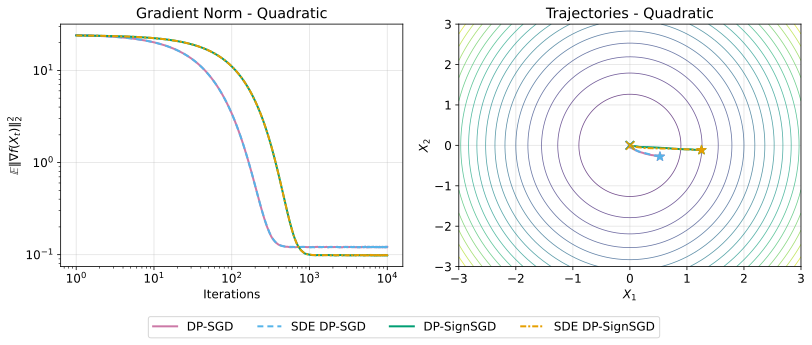

In [10]:

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.5))
plot_gradient_norm(ax=axes[0])
plot_trajectories(ax=axes[1])

handles, labels = axes[0].get_legend_handles_labels()
for ax in axes:
    leg = ax.get_legend()
    if leg is not None:
        leg.remove()
fig.legend(handles, labels, loc="lower center", ncol=4, frameon=True, bbox_to_anchor=(0.5, -0.08))
fig.tight_layout()
fig.savefig("figure_c1_quadratic_only_replication.png", dpi=250, bbox_inches="tight")
fig.savefig("figure_c1_quadratic_only_replication.pdf", bbox_inches="tight")
plt.show()
